<a href="https://colab.research.google.com/github/Shrutisru/New_Project/blob/main/week5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root : /content/uav_project/data/mav0
সব পাথ ঠিক আছে ✅
OpenCV: 5.0.0
ব্যবহারযোগ্য ফ্রেম: 3638


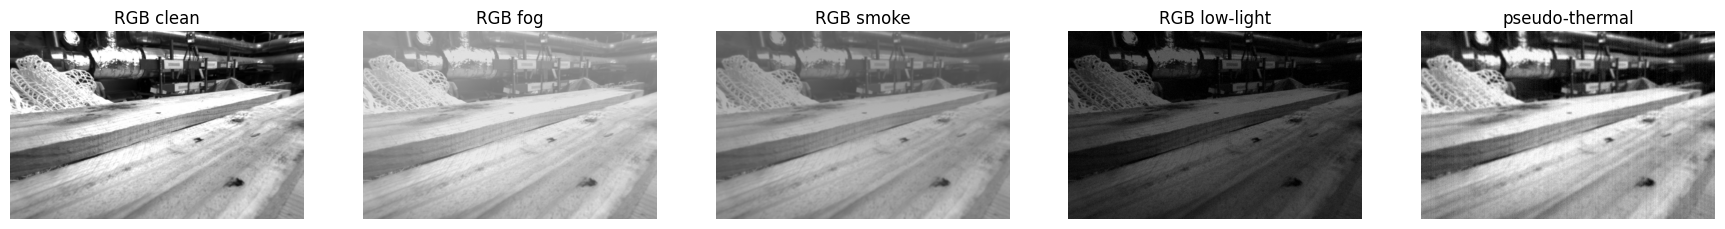


[thermal] branch শুরু (modality=thermal, mode=None)
  [thermal] Frame   500/3638 | valid steps: 425
  [thermal] Frame  1000/3638 | valid steps: 715
  [thermal] Frame  1500/3638 | valid steps: 1144
  [thermal] Frame  2000/3638 | valid steps: 1566
  [thermal] Frame  2500/3638 | valid steps: 1966
  [thermal] Frame  3000/3638 | valid steps: 2404
  [thermal] Frame  3500/3638 | valid steps: 2727
[thermal] সম্পন্ন — valid ধাপ: 78.3% | mean features: 2423 | mean inlier ratio: 0.803

[rgb-clean] branch শুরু (modality=rgb, mode=None)
  [rgb-clean] Frame   500/3638 | valid steps: 364
  [rgb-clean] Frame  1000/3638 | valid steps: 502
  [rgb-clean] Frame  1500/3638 | valid steps: 914
  [rgb-clean] Frame  2000/3638 | valid steps: 1319
  [rgb-clean] Frame  2500/3638 | valid steps: 1736
  [rgb-clean] Frame  3000/3638 | valid steps: 2161
  [rgb-clean] Frame  3500/3638 | valid steps: 2483
[rgb-clean] সম্পন্ন — valid ধাপ: 71.3% | mean features: 2453 | mean inlier ratio: 0.867

[rgb-fog] branch শুরু (mod

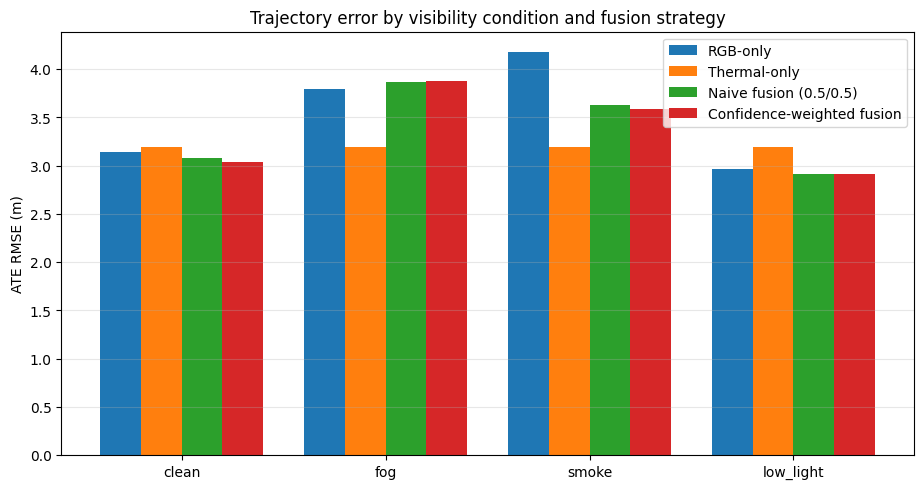

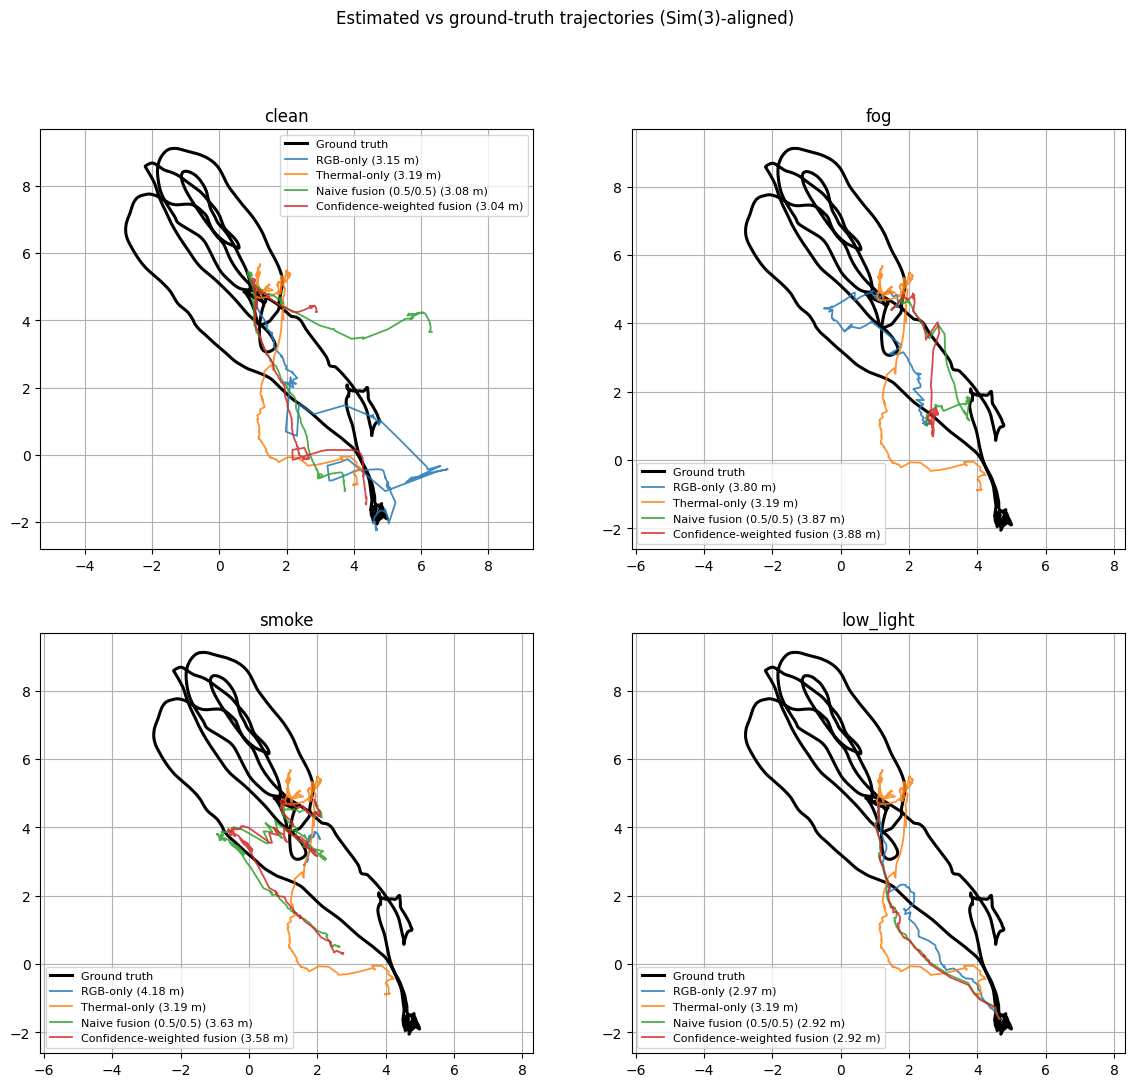

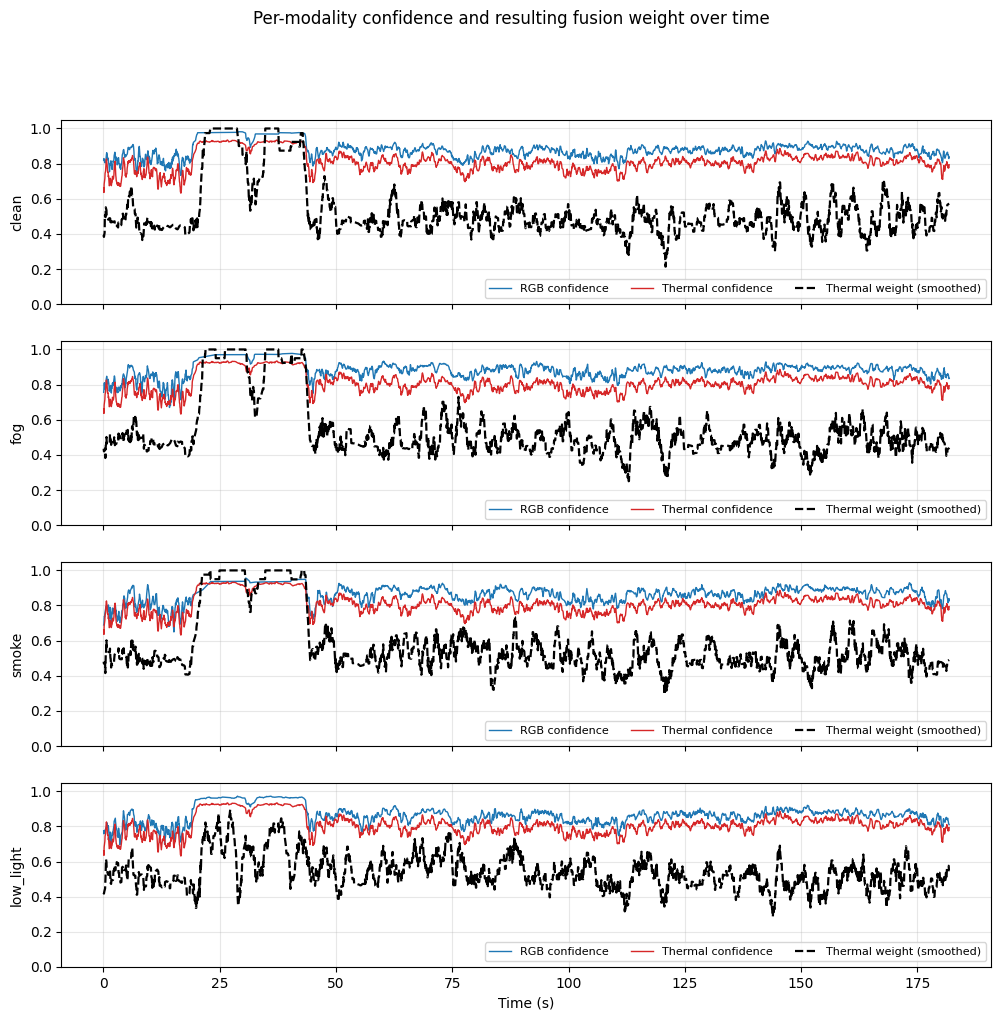


WEEK 5 — WEIGHT_POWER sensitivity (ATE RMSE, m)
         power  clean    fog  smoke  low_light
           1.0 3.0503 3.8729 3.5969     2.9181
           2.0 3.0398 3.8769 3.5845     2.9186
           4.0 3.0677 3.8810 3.5440     2.9202
           8.0 3.0815 3.8854 3.5560     2.9247
naive(0.5/0.5) 3.0811 3.8668 3.6337     2.9177

WEEK 5 — Thermal branch validation (feature statistics)
               source  n_images  mean_features  mean_entropy  mean_inlier_ratio  n_pairs
    EuRoC RGB (clean)      3638       2453.123         7.189              0.867     2594
pseudo-thermal (ours)      3638       2423.388         7.563              0.803     2847

ℹ️ আসল thermal ডেটাসেটের পাথ এখনো দেওয়া হয়নি — THERMAL_DIRS পূরণ করে এই সেলটা আবার চালান।

সব ফলাফল সেভ হয়েছে: /content/uav_project/results_week5


In [2]:
# -*- coding: utf-8 -*-
"""
Week 5 — Confidence-Weighted Local Fusion of RGB + Thermal VO
==============================================================
লক্ষ্য (roadmap):
  1. Thermal-based feature tracking branch যোগ করা (HIT-UAV / FLIR ADAS-এ আলাদাভাবে validate)
  2. RGB + thermal estimate confidence দিয়ে ওজন করে মেলানো
  3. RGB-only এবং naive (সমান ওজনের) fusion-এর সাথে তুলনা

⚠️ সবচেয়ে গুরুত্বপূর্ণ সীমাবদ্ধতা (supervisor-কে অবশ্যই জানাবেন):
  EuRoC MAV-তে কোনো thermal ক্যামেরা নেই, আর HIT-UAV / FLIR ADAS-এ ground-truth
  trajectory নেই। তাই ATE/RPE-র তুলনা করার জন্য EuRoC-এর পরিষ্কার ফ্রেম থেকে একটা
  "pseudo-thermal" ছবি বানানো হচ্ছে (কম resolution, blur, কম contrast, noise)। ধারণা
  হলো thermal দৃশ্যমানতার অবনতিতে (fog/smoke/low-light) প্রভাবিত হয় না, কিন্তু
  পরিষ্কার অবস্থায় RGB-র চেয়ে নিম্নমানের। এটা fusion MECHANISM-এর আচরণ দেখায়,
  আসল RGB-thermal hardware-এর পারফরম্যান্স নয়। আসল thermal ছবির উপর শুধু feature-
  statistics validate করা হয় (ধাপ ১৬)।

Design নোট:
  - প্রতিটা branch (RGB, thermal) শুধু পরপর ফ্রেম (i-1 → i) জোড়ায় relative motion বের করে,
    যাতে দুই branch-এর মোশন সরাসরি তুলনীয় হয়। তাই RGB-only সংখ্যা Week 3/4-এর
    সংখ্যার সাথে হুবহু মিলবে না — তুলনা করবেন শুধু এই স্ক্রিপ্টের ভেতরেই।
  - Fusion হয় relative-motion স্তরে (rotation, translation direction, scale ratio),
    absolute trajectory মেলানো হয় না (দুই branch-এর scale/drift আলাদা বলে)।
  - Naive ও confidence-weighted দুটোতেই একটা branch ব্যর্থ হলে অন্যটা ব্যবহার হয়,
    তাই দুটোর পার্থক্য শুধু "দুটোই কাজ করলে কাকে কতটা ওজন" থেকে আসে।

Colab-এ ধাপে ধাপে (উপর থেকে নিচে) রান করুন।
"""

# ============================================================
# ধাপ ১ — Drive মাউন্ট, ডেটাসেট প্রস্তুত
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

zip_path = "/content/drive/MyDrive/MH_01_easy.zip"
work_dir = "/content/uav_project"
extract_dir = f"{work_dir}/data"

os.makedirs(work_dir, exist_ok=True)
assert os.path.exists(zip_path), f"ZIP ফাইল পাওয়া যায়নি: {zip_path}"

dataset_root = None
if os.path.exists(extract_dir):
    for root, dirs, files in os.walk(extract_dir):
        if "mav0" in dirs:
            dataset_root = os.path.join(root, "mav0")
            break

if dataset_root is None:
    os.makedirs(extract_dir, exist_ok=True)
    print("Extracting ZIP...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    for root, dirs, files in os.walk(extract_dir):
        if "mav0" in dirs:
            dataset_root = os.path.join(root, "mav0")
            break

assert dataset_root is not None, "mav0 ফোল্ডার খুঁজে পাওয়া যায়নি।"

cam0_dir = os.path.join(dataset_root, "cam0")
cam0_data = os.path.join(cam0_dir, "data")
cam0_csv = os.path.join(cam0_dir, "data.csv")
sensor_yaml = os.path.join(cam0_dir, "sensor.yaml")
gt_csv = os.path.join(dataset_root, "state_groundtruth_estimate0", "data.csv")

for p in [cam0_data, cam0_csv, sensor_yaml, gt_csv]:
    assert os.path.exists(p), f"পাওয়া যায়নি: {p}"

print("Dataset root :", dataset_root)
print("সব পাথ ঠিক আছে ✅")


# ============================================================
# ধাপ ২ — ইম্পোর্ট ও রেজাল্ট ফোল্ডার
# ============================================================

# !pip install -q opencv-python numpy pandas matplotlib scipy pyyaml

import cv2
import yaml
import glob
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.spatial.transform import Rotation as SciRot

results_dir = os.path.join(work_dir, "results_week5")
if os.path.exists(results_dir):
    shutil.rmtree(results_dir)
os.makedirs(results_dir, exist_ok=True)

print("OpenCV:", cv2.__version__)


# ============================================================
# ধাপ ৩ — ক্যালিব্রেশন লোড
# ============================================================

with open(sensor_yaml, "r") as f:
    sensor_data = yaml.safe_load(f)

fx, fy, cx, cy = sensor_data["intrinsics"]
dist_coeffs = np.array(sensor_data["distortion_coefficients"], dtype=np.float64)
K = np.array([[fx, 0.0, cx], [0.0, fy, cy], [0.0, 0.0, 1.0]], dtype=np.float64)


# ============================================================
# ধাপ ৪ — CSV লোড ও কমন টাইম-উইন্ডো
# ============================================================

cam_df = pd.read_csv(cam0_csv)
gt_df = pd.read_csv(gt_csv)

cam_time_col, cam_file_col = "#timestamp [ns]", "filename"
gt_time_col = "#timestamp"
gt_x_col, gt_y_col, gt_z_col = " p_RS_R_x [m]", " p_RS_R_y [m]", " p_RS_R_z [m]"

cam_df[cam_time_col] = pd.to_numeric(cam_df[cam_time_col])
gt_df[gt_time_col] = pd.to_numeric(gt_df[gt_time_col])

start_time = max(cam_df[cam_time_col].min(), gt_df[gt_time_col].min())
end_time = min(cam_df[cam_time_col].max(), gt_df[gt_time_col].max())
cam_df = cam_df[(cam_df[cam_time_col] >= start_time) &
                (cam_df[cam_time_col] <= end_time)].reset_index(drop=True)

print("ব্যবহারযোগ্য ফ্রেম:", len(cam_df))


# ============================================================
# ধাপ ৫ — কনফিগারেশন (সব টিউনযোগ্য মান এক জায়গায়)
# ============================================================

SEED = 0
SEVERITY = "moderate"          # Week 3-এর মতোই

# --- Confidence স্কোরের ওজন ---
# Week 4-এর ফলাফল (window-ভিত্তিক Spearman r): inlier_ratio চারটা condition-এই ঋণাত্মক
# (-0.12 থেকে -0.38), feature_count প্রায় শূন্য, entropy অস্থির (fog-এ +0.37, low_light-এ -0.62)।
# তাই ডিফল্ট: শুধু inlier_ratio। Week 4-এর ধাপ ১০-গ-র held-out ফল অন্য কিছু বললে এখানে বদলান।
CONF_WEIGHTS = {"feature": 0.0, "inlier": 1.0, "entropy": 0.0}
CONF_SMOOTH_WINDOW = 5         # কতগুলো সফল ধাপের causal (শুধু অতীত) গড়
WEIGHT_POWER = 2.0             # ওজন ∝ confidence^POWER (বড় মান = বেশি পার্থক্য)

# --- Pseudo-thermal-এর অনুমানকৃত বৈশিষ্ট্য (নথিভুক্ত assumption, টিউনযোগ্য) ---
THERMAL_PARAMS = {
    "downscale": 0.5,    # thermal সেন্সরের resolution সাধারণত অনেক কম
    "blur_sigma": 1.2,   # thermal optics-এর blur
    "contrast": 0.5,     # তাপমাত্রার range সংকীর্ণ হওয়ায় কম contrast
    "noise_std": 4.0,    # temporal noise
    "fpn_std": 2.0,      # fixed-pattern (column) noise
}

NFEATURES_MAX = 2500
MAX_ENTROPY = 8.0
MIN_COMMON_PTS_FOR_SCALE = 6
RATIO_CLIP = (0.2, 5.0)


# ============================================================
# ধাপ ৬ — Degradation (RGB-তে প্রযোজ্য) ও pseudo-thermal
# ============================================================

SEVERITY_PRESETS = {
    "fog": {
        "mild":     {"beta": 0.6, "A": 200},
        "moderate": {"beta": 1.2, "A": 210},
        "severe":   {"beta": 2.0, "A": 220},
    },
    "smoke": {
        "mild":     {"beta": 0.7, "A": 130, "blur": 3},
        "moderate": {"beta": 1.3, "A": 120, "blur": 5},
        "severe":   {"beta": 2.1, "A": 110, "blur": 7},
    },
    "low_light": {
        "mild":     {"gain": 0.65, "gamma": 1.15, "noise_std": 3},
        "moderate": {"gain": 0.45, "gamma": 1.35, "noise_std": 5},
        "severe":   {"gain": 0.28, "gamma": 1.6,  "noise_std": 7},
    },
}


def _depth_proxy(h, w):
    d = np.linspace(1.0, 0.15, h).reshape(h, 1)
    return np.repeat(d, w, axis=1)


def degrade_image(img, mode=None, severity="moderate"):
    if mode is None or mode == "clean":
        return img
    p = SEVERITY_PRESETS[mode][severity]
    h, w = img.shape[:2]
    img_f = img.astype(np.float32)

    if mode in ("fog", "smoke"):
        transmission = np.exp(-p["beta"] * _depth_proxy(h, w)).astype(np.float32)
        out = img_f * transmission + p["A"] * (1.0 - transmission)
        if mode == "smoke":
            k = p["blur"]
            out = cv2.GaussianBlur(out, (k, k), 0)
    else:  # low_light
        out = img_f * p["gain"]
        out = 255.0 * np.power(np.clip(out / 255.0, 0, 1), p["gamma"])
        out = out + np.random.normal(0, p["noise_std"], out.shape).astype(np.float32)

    return np.clip(out, 0, 255).astype(np.uint8)


_fpn_cache = {}


def make_pseudo_thermal(clean_img, rng, p=None):
    """
    পরিষ্কার গ্রেস্কেল ফ্রেম থেকে thermal-সদৃশ ছবি বানায়।
    দৃশ্যমানতার degradation (fog/smoke/low-light) এখানে প্রয়োগ করা হয় না —
    এটাই "thermal এই অবস্থায় অপ্রভাবিত" ধারণার প্রতিফলন।
    """
    p = p or THERMAL_PARAMS
    h, w = clean_img.shape[:2]
    img = clean_img.astype(np.float32)

    small = cv2.resize(img, (max(int(w * p["downscale"]), 1), max(int(h * p["downscale"]), 1)),
                       interpolation=cv2.INTER_AREA)
    img = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    img = cv2.GaussianBlur(img, (0, 0), p["blur_sigma"])

    m = float(img.mean())
    img = m + p["contrast"] * (img - m)

    if w not in _fpn_cache:
        _fpn_cache[w] = np.random.default_rng(SEED + 1).normal(0, p["fpn_std"], w).astype(np.float32)
    img = img + _fpn_cache[w][None, :]
    img = img + rng.normal(0, p["noise_std"], img.shape).astype(np.float32)

    # 8-bit thermal output-এ সাধারণত AGC (auto gain control) থাকে — তাই re-stretch
    lo, hi = np.percentile(img, (1, 99))
    img = np.clip((img - lo) / max(hi - lo, 1e-6), 0.0, 1.0) * 255.0
    return img.astype(np.uint8)


def load_clean(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    return cv2.undistort(img, K, dist_coeffs)


# ---- ৪টা ছবি পাশাপাশি যাচাই (clean / fog-RGB / low-light-RGB / pseudo-thermal) ----
_sample_path = os.path.join(cam0_data, str(cam_df.iloc[min(500, len(cam_df) - 1)][cam_file_col]))
_clean = load_clean(_sample_path)
_rng_prev = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (title, im) in zip(axes, [
    ("RGB clean", _clean),
    ("RGB fog", degrade_image(_clean, "fog", SEVERITY)),
    ("RGB smoke", degrade_image(_clean, "smoke", SEVERITY)),
    ("RGB low-light", degrade_image(_clean, "low_light", SEVERITY)),
    ("pseudo-thermal", make_pseudo_thermal(_clean, _rng_prev)),
]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.savefig(os.path.join(results_dir, "modality_preview.png"), dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# ধাপ ৭ — Confidence স্কোর
# ============================================================

def compute_entropy(img):
    hist = cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()
    hist = hist / (hist.sum() + 1e-12)
    hist = hist[hist > 0]
    return float(-np.sum(hist * np.log2(hist)))


def compute_confidence(feat, inlier, ent):
    wf, wi, we = CONF_WEIGHTS["feature"], CONF_WEIGHTS["inlier"], CONF_WEIGHTS["entropy"]
    s = wf + wi + we
    return (wf * min(feat / NFEATURES_MAX, 1.0)
            + wi * float(np.clip(inlier, 0, 1))
            + we * float(np.clip(ent / MAX_ENTROPY, 0, 1))) / s


def safe_nanmean(x):
    """সব মান NaN হলে warning ছাড়াই NaN ফেরত দেয় (যেমন একটা branch পুরোপুরি ব্যর্থ হলে)।"""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    return float(x.mean()) if len(x) else float("nan")


def causal_smooth(conf, valid, window):
    """শুধু অতীতের সফল ধাপের গড় — ভবিষ্যৎ তথ্য ব্যবহার না করায় real-time-এ প্রযোজ্য।"""
    out = np.full(len(conf), np.nan)
    hist = []
    for i in range(len(conf)):
        if valid[i] and not np.isnan(conf[i]):
            hist.append(conf[i])
            hist = hist[-window:]
            out[i] = float(np.mean(hist))
    return out


# ============================================================
# ধাপ ৮ — একটা frame-pair থেকে relative motion (RGB ও thermal দুটোর জন্যই এক কোড)
# ============================================================

orb = cv2.ORB_create(nfeatures=NFEATURES_MAX, scaleFactor=1.2, nlevels=8,
                     edgeThreshold=31, patchSize=31, fastThreshold=20)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)


def proj(K_mat, R_mat, t_vec):
    return K_mat @ np.hstack([R_mat, np.asarray(t_vec).reshape(3, 1)])


def triangulate(P1, P2, pts1, pts2):
    X = cv2.triangulatePoints(P1, P2, pts1.T.astype(np.float64), pts2.T.astype(np.float64))
    return (X[:3] / X[3]).T


def estimate_pair(prev_kp, prev_des, curr_kp, curr_des, prev_link, prev_R, prev_t):
    """
    রিটার্ন: dict(R, t (unit), ratio, inlier_ratio, link) অথবা ব্যর্থ হলে None।
    ratio = (এই ধাপের baseline) / (আগের ধাপের baseline) — দুই branch-এ একই ভৌত রাশি,
    তাই fusion-এ সরাসরি মেলানো যায়।
    """
    try:
        knn = bf.knnMatch(prev_des, curr_des, k=2)
    except cv2.error:
        return None
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < 8:
        return None

    pts_prev = np.float32([prev_kp[m.queryIdx].pt for m in good])
    pts_curr = np.float32([curr_kp[m.trainIdx].pt for m in good])
    prev_idx = np.array([m.queryIdx for m in good])
    curr_idx = np.array([m.trainIdx for m in good])

    E, mask_E = cv2.findEssentialMat(pts_prev, pts_curr, K, method=cv2.RANSAC,
                                     prob=0.999, threshold=1.0)
    if E is None or mask_E is None:
        return None
    if E.shape != (3, 3):
        E = E[:3, :]

    inl = mask_E.ravel().astype(bool)
    if inl.sum() < 8:
        return None
    p_in, c_in = pts_prev[inl], pts_curr[inl]
    pi_in, ci_in = prev_idx[inl], curr_idx[inl]

    try:
        retval, R_rel, t_rel, _ = cv2.recoverPose(E, p_in, c_in, K)
    except cv2.error:
        return None
    if retval < 8:
        return None
    t_unit = t_rel.reshape(3)

    ratio = np.nan
    if prev_link is not None and prev_R is not None and len(prev_link) > 0:
        common = np.intersect1d(pi_in, np.array(list(prev_link.keys())))
        if len(common) >= MIN_COMMON_PTS_FOR_SCALE:
            pts_tm2 = np.array([prev_link[k] for k in common], dtype=np.float64)
            pts_tm1 = np.array([prev_kp[k].pt for k in common], dtype=np.float64)
            this_map = dict(zip(pi_in.tolist(), c_in.tolist()))
            pts_t = np.array([this_map[k] for k in common], dtype=np.float64)

            P_ref = proj(K, np.eye(3), np.zeros(3))
            P_tm2 = proj(K, prev_R.T, -prev_R.T @ prev_t)
            P_t = proj(K, R_rel, t_unit)

            dA = pdist(triangulate(P_tm2, P_ref, pts_tm2, pts_tm1))
            dB = pdist(triangulate(P_ref, P_t, pts_tm1, pts_t))
            ok = (dA > 1e-6) & (dB > 1e-6) & np.isfinite(dA) & np.isfinite(dB)
            if np.any(ok):
                ratio = float(np.median(dA[ok] / dB[ok]))

    return {
        "R": R_rel, "t": t_unit, "ratio": ratio,
        "inlier_ratio": float(inl.sum()) / len(good),
        "link": dict(zip(ci_in.tolist(), p_in.tolist())),
    }


# ============================================================
# ধাপ ৯ — একটা branch চালানো (প্রতিটা পরপর ফ্রেম-জোড়ার ফলাফল সংরক্ষণ)
# ============================================================

def run_branch(modality, mode=None, severity="moderate", label="", verbose=True):
    """
    modality = "rgb"     → ছবি degrade হয় (mode অনুযায়ী)
    modality = "thermal" → পরিষ্কার ফ্রেম থেকে pseudo-thermal, degradation ছাড়া
    """
    n = len(cam_df)
    out = {
        "label": label, "modality": modality,
        "valid": np.zeros(n, dtype=bool),
        "R": np.tile(np.eye(3), (n, 1, 1)),
        "t": np.zeros((n, 3)),
        "ratio": np.full(n, np.nan),
        "inlier_ratio": np.full(n, np.nan),
        "feat": np.zeros(n),
        "entropy": np.zeros(n),
        "conf_raw": np.full(n, np.nan),
    }
    np.random.seed(SEED)                       # low_light noise reproducible
    rng = np.random.default_rng(SEED)          # thermal temporal noise reproducible

    def get_img(i):
        clean = load_clean(os.path.join(cam0_data, str(cam_df.iloc[i][cam_file_col])))
        if clean is None:
            return None
        if modality == "rgb":
            return degrade_image(clean, mode, severity)
        return make_pseudo_thermal(clean, rng)

    if verbose:
        print(f"\n[{label}] branch শুরু (modality={modality}, mode={mode})")

    prev_img = get_img(0)
    prev_kp, prev_des = (None, None) if prev_img is None else orb.detectAndCompute(prev_img, None)
    out["feat"][0] = 0 if prev_kp is None else len(prev_kp)
    if prev_img is not None:
        out["entropy"][0] = compute_entropy(prev_img)

    prev_link, prev_R, prev_t = None, None, None

    for i in range(1, n):
        curr_img = get_img(i)
        if curr_img is None:
            prev_kp, prev_des, prev_link, prev_R, prev_t = None, None, None, None, None
            continue

        curr_kp, curr_des = orb.detectAndCompute(curr_img, None)
        out["feat"][i] = 0 if curr_kp is None else len(curr_kp)
        out["entropy"][i] = compute_entropy(curr_img)

        res = None
        if (prev_des is not None and curr_des is not None
                and len(prev_kp) >= 20 and len(curr_kp) >= 20):
            res = estimate_pair(prev_kp, prev_des, curr_kp, curr_des, prev_link, prev_R, prev_t)

        if res is not None:
            out["valid"][i] = True
            out["R"][i] = res["R"]
            out["t"][i] = res["t"]
            out["ratio"][i] = res["ratio"]
            out["inlier_ratio"][i] = res["inlier_ratio"]
            out["conf_raw"][i] = compute_confidence(out["feat"][i], res["inlier_ratio"],
                                                    out["entropy"][i])
            prev_link, prev_R, prev_t = res["link"], res["R"], res["t"]
        else:
            prev_link, prev_R, prev_t = None, None, None

        # সবসময় পরের ফ্রেমে এগোই (পরপর-জোড়া নীতি) — তাই দুই branch-এর ধাপ মেলে
        prev_kp, prev_des = curr_kp, curr_des

        if verbose and i % 500 == 0:
            print(f"  [{label}] Frame {i:5d}/{n} | valid steps: {int(out['valid'].sum())}")

    out["conf"] = causal_smooth(out["conf_raw"], out["valid"], CONF_SMOOTH_WINDOW)
    out["valid_pct"] = 100.0 * out["valid"][1:].mean()
    if verbose:
        print(f"[{label}] সম্পন্ন — valid ধাপ: {out['valid_pct']:.1f}% | "
              f"mean features: {out['feat'][1:].mean():.0f} | "
              f"mean inlier ratio: {safe_nanmean(out['inlier_ratio']):.3f}")
    return out


# ============================================================
# ধাপ ১০ — Fusion (relative-motion স্তরে)
# ============================================================

def fuse_rotations(Ra, Rb, w_b):
    """দুই rotation-এর ওজনযুক্ত গড় (geodesic interpolation): w_b=0 → Ra, w_b=1 → Rb।"""
    delta = SciRot.from_matrix(Ra.T @ Rb).as_rotvec()
    return Ra @ SciRot.from_rotvec(w_b * delta).as_matrix()


def fuse_ratio(r_rgb, r_th, w_rgb, w_th):
    """scale-ratio-র ওজনযুক্ত জ্যামিতিক গড় (log-domain)।"""
    items = [(r, w) for r, w in ((r_rgb, w_rgb), (r_th, w_th)) if not np.isnan(r) and w > 0]
    if not items:
        return 1.0
    ws = sum(w for _, w in items)
    return float(np.exp(sum(w * np.log(max(r, 1e-6)) for r, w in items) / ws))


def fuse(rgb, th, method, power=None):
    """
    method: "rgb_only" | "thermal_only" | "naive" | "confidence"
    রিটার্ন: trajectory (positions, rotations, timestamps) + fusion পরিসংখ্যান।
    """
    power = WEIGHT_POWER if power is None else power
    n = len(cam_df)
    ts_all = cam_df[cam_time_col].to_numpy(dtype=np.int64)

    R_wc = np.eye(3)
    t_wc = np.zeros((3, 1))
    positions, rotations, timestamps = [t_wc.reshape(3)], [R_wc.copy()], [int(ts_all[0])]
    step_scale = 1.0
    n_both = n_single = 0
    wt_times, wt_vals = [], []

    for i in range(1, n):
        use_r = bool(rgb["valid"][i]) and method != "thermal_only"
        use_t = bool(th["valid"][i]) and method != "rgb_only"
        if not (use_r or use_t):
            continue

        if use_r and use_t:
            if method == "naive":
                w_r = w_t = 0.5
            else:
                c_r = max(float(np.nan_to_num(rgb["conf"][i], nan=0.5)), 1e-3)
                c_t = max(float(np.nan_to_num(th["conf"][i], nan=0.5)), 1e-3)
                w_r, w_t = c_r ** power, c_t ** power
                s = w_r + w_t
                w_r, w_t = w_r / s, w_t / s
            n_both += 1
            R_rel = fuse_rotations(rgb["R"][i], th["R"][i], w_t)
            d = w_r * rgb["t"][i] + w_t * th["t"][i]
            if np.dot(rgb["t"][i], th["t"][i]) < 0 or np.linalg.norm(d) < 1e-6:
                d = rgb["t"][i] if w_r >= w_t else th["t"][i]   # দিক মেলেনি → বেশি ওজনেরটা
            t_dir = d / np.linalg.norm(d)
        elif use_r:
            w_r, w_t = 1.0, 0.0
            R_rel, t_dir = rgb["R"][i], rgb["t"][i]
            n_single += 1
        else:
            w_r, w_t = 0.0, 1.0
            R_rel, t_dir = th["R"][i], th["t"][i]
            n_single += 1

        ratio = fuse_ratio(rgb["ratio"][i] if use_r else np.nan,
                           th["ratio"][i] if use_t else np.nan, w_r, w_t)
        step_scale *= float(np.clip(ratio, RATIO_CLIP[0], RATIO_CLIP[1]))

        R_wc = R_wc @ R_rel.T
        t_wc = t_wc - R_wc @ (t_dir * step_scale).reshape(3, 1)

        positions.append(t_wc.reshape(3))
        rotations.append(R_wc.copy())
        timestamps.append(int(ts_all[i]))
        wt_times.append(int(ts_all[i]))
        wt_vals.append(w_t)

    return {
        "method": method,
        "positions": np.asarray(positions, dtype=np.float64),
        "rotations": np.asarray(rotations, dtype=np.float64),
        "timestamps": np.asarray(timestamps, dtype=np.int64),
        "coverage_pct": 100.0 * (len(positions) - 1) / (n - 1),
        "both_pct": 100.0 * n_both / max(n_both + n_single, 1),
        "mean_thermal_weight": float(np.mean(wt_vals)) if wt_vals else float("nan"),
        "wt_times": np.asarray(wt_times, dtype=np.int64),
        "wt_vals": np.asarray(wt_vals, dtype=np.float64),
    }


# ============================================================
# ধাপ ১১ — মূল্যায়ন (Sim(3) alignment, ATE, ~১ সেকেন্ড RPE)
# ============================================================

gt_time = gt_df[gt_time_col].to_numpy(dtype=np.float64)
gt_position = np.column_stack([
    gt_df[gt_x_col].to_numpy(dtype=np.float64),
    gt_df[gt_y_col].to_numpy(dtype=np.float64),
    gt_df[gt_z_col].to_numpy(dtype=np.float64),
])
gt_time, _u = np.unique(gt_time, return_index=True)
gt_position = gt_position[_u]


def interpolate_gt(ts_ns):
    return np.column_stack([np.interp(ts_ns.astype(np.float64), gt_time, gt_position[:, a])
                            for a in range(3)])


def umeyama_alignment(source, target, with_scale=True):
    source, target = np.asarray(source), np.asarray(target)
    n = source.shape[0]
    mu_s, mu_t = source.mean(axis=0), target.mean(axis=0)
    sc, tc = source - mu_s, target - mu_t
    U, D, Vt = np.linalg.svd((tc.T @ sc) / n)
    S = np.eye(3)
    if np.linalg.det(U @ Vt) < 0:
        S[-1, -1] = -1
    R = U @ S @ Vt
    var = np.sum(sc ** 2) / n
    scale = (np.sum(D * np.diag(S)) / var) if (with_scale and var > 1e-12) else 1.0
    t = mu_t - scale * (R @ mu_s)
    return scale * (R @ source.T).T + t, scale


def evaluate_run(run, rpe_window_sec=1.0):
    if len(run["positions"]) < 10:
        run.update({"aligned": None, "gt_interp": None, "ate_errors": np.array([]),
                    "ate_rmse": float("nan"), "rpe_rmse": float("nan")})
        return run

    gt_i = interpolate_gt(run["timestamps"])
    aligned, _ = umeyama_alignment(run["positions"], gt_i, with_scale=True)
    ate = np.linalg.norm(aligned - gt_i, axis=1)

    ts = run["timestamps"]
    delta_ns = int(rpe_window_sec * 1e9)
    rpe = []
    for i in range(len(ts)):
        j = int(np.searchsorted(ts, ts[i] + delta_ns))
        if j >= len(ts):
            break
        rpe.append(np.linalg.norm((aligned[j] - aligned[i]) - (gt_i[j] - gt_i[i])))
    rpe = np.asarray(rpe)

    run.update({
        "aligned": aligned, "gt_interp": gt_i, "ate_errors": ate,
        "ate_rmse": float(np.sqrt(np.mean(ate ** 2))),
        "rpe_rmse": float(np.sqrt(np.mean(rpe ** 2))) if len(rpe) else float("nan"),
    })
    return run


# ============================================================
# ধাপ ১২ — Branch চালানো (সবচেয়ে সময়সাপেক্ষ ধাপ)
# ============================================================
# মোট ৫টা branch রান: thermal ১ বার (condition-নিরপেক্ষ) + RGB ৪ বার।
# ⚠️ প্রথমবার শুধু "কোড চলছে কিনা" দেখতে চাইলে এই সেলের আগে চালান:
#     cam_df = cam_df.iloc[:1000].reset_index(drop=True)
# (এতে সংখ্যা অর্থবহ হবে না, শুধু error আছে কিনা বোঝা যাবে)

conditions = [(None, "clean"), ("fog", "fog"), ("smoke", "smoke"), ("low_light", "low_light")]

thermal_branch = run_branch("thermal", label="thermal")
rgb_branches = {}
for mode, label in conditions:
    rgb_branches[label] = run_branch("rgb", mode, SEVERITY, label=f"rgb-{label}")


# ============================================================
# ধাপ ১৩ — ৪টা পদ্ধতির তুলনা (Presentation 5-এর মূল ডেলিভারেবল)
# ============================================================

METHODS = ["rgb_only", "thermal_only", "naive", "confidence"]
METHOD_NAMES = {"rgb_only": "RGB-only", "thermal_only": "Thermal-only",
                "naive": "Naive fusion (0.5/0.5)", "confidence": "Confidence-weighted fusion"}

all_runs = {}
rows = []
for _, label in conditions:
    for method in METHODS:
        run = evaluate_run(fuse(rgb_branches[label], thermal_branch, method))
        all_runs[(label, method)] = run
        rows.append({
            "Condition": label,
            "Method": METHOD_NAMES[method],
            "ATE RMSE (m)": round(run["ate_rmse"], 4),
            "RPE RMSE 1s (m)": round(run["rpe_rmse"], 4),
            "Coverage (%)": round(run["coverage_pct"], 1),
            "Both-branch steps (%)": round(run["both_pct"], 1),
            "Mean thermal weight": round(run["mean_thermal_weight"], 3),
        })

table = pd.DataFrame(rows)
base = table[table["Method"] == METHOD_NAMES["rgb_only"]].set_index("Condition")["ATE RMSE (m)"]
table["ATE vs RGB-only (%)"] = [
    round(100.0 * (r["ATE RMSE (m)"] - base[r["Condition"]]) / base[r["Condition"]], 1)
    if base[r["Condition"]] > 0 else np.nan for _, r in table.iterrows()
]

print("\n" + "=" * 100)
print("WEEK 5 — RGB-only vs Thermal-only vs Naive vs Confidence-weighted fusion")
print("=" * 100)
print(table.to_string(index=False))
print("\n(ATE vs RGB-only: ঋণাত্মক = RGB-only-র চেয়ে ভালো)")
print("মনে রাখবেন: একটা রান, একটা sequence — ছোট পার্থক্য (~০.২ মি) noise হতে পারে।")
table.to_csv(os.path.join(results_dir, "week5_fusion_comparison.csv"), index=False)


# ============================================================
# ধাপ ১৪ — প্লট
# ============================================================

cond_names = [c for _, c in conditions]

# (ক) ATE গ্রুপড বার চার্ট
fig, ax = plt.subplots(figsize=(11, 5.5))
width = 0.2
for k, method in enumerate(METHODS):
    vals = [all_runs[(c, method)]["ate_rmse"] for c in cond_names]
    ax.bar(np.arange(len(cond_names)) + (k - 1.5) * width, vals, width, label=METHOD_NAMES[method])
ax.set_xticks(np.arange(len(cond_names)))
ax.set_xticklabels(cond_names)
ax.set_ylabel("ATE RMSE (m)")
ax.set_title("Trajectory error by visibility condition and fusion strategy")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.savefig(os.path.join(results_dir, "ate_comparison_bars.png"), dpi=200, bbox_inches="tight")
plt.show()

# (খ) প্রতিটা condition-এর trajectory
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, c in zip(axes.ravel(), cond_names):
    ref = all_runs[(c, "rgb_only")]
    if ref["gt_interp"] is not None:
        ax.plot(ref["gt_interp"][:, 0], ref["gt_interp"][:, 1], color="black", lw=2.2, label="Ground truth")
    for method in METHODS:
        r = all_runs[(c, method)]
        if r["aligned"] is None:
            continue
        ax.plot(r["aligned"][:, 0], r["aligned"][:, 1], lw=1.3, alpha=0.85,
                label=f"{METHOD_NAMES[method]} ({r['ate_rmse']:.2f} m)")
    ax.set_title(c)
    ax.axis("equal")
    ax.grid(True)
    ax.legend(fontsize=8)
plt.suptitle("Estimated vs ground-truth trajectories (Sim(3)-aligned)")
plt.savefig(os.path.join(results_dir, "trajectory_comparison_by_condition.png"),
            dpi=200, bbox_inches="tight")
plt.show()

# (গ) Confidence ও thermal ওজন সময়ের সাথে — "confidence কীভাবে ওজন বদলায়" তার চিত্র
t0 = cam_df[cam_time_col].iloc[0]
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, c in zip(axes, cond_names):
    rb = rgb_branches[c]
    ts = (cam_df[cam_time_col].to_numpy() - t0) / 1e9
    ax.plot(ts[rb["valid"]], rb["conf"][rb["valid"]], lw=1, color="tab:blue", label="RGB confidence")
    ax.plot(ts[thermal_branch["valid"]], thermal_branch["conf"][thermal_branch["valid"]],
            lw=1, color="tab:red", label="Thermal confidence")
    cr = all_runs[(c, "confidence")]
    if len(cr["wt_times"]):
        w = pd.Series(cr["wt_vals"]).rolling(20, min_periods=1).mean().to_numpy()
        ax.plot((cr["wt_times"] - t0) / 1e9, w, "k--", lw=1.6, label="Thermal weight (smoothed)")
    ax.set_ylabel(c)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right", fontsize=8, ncol=3)
axes[-1].set_xlabel("Time (s)")
plt.suptitle("Per-modality confidence and resulting fusion weight over time")
plt.savefig(os.path.join(results_dir, "confidence_and_weights_over_time.png"),
            dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# ধাপ ১৫ — Sensitivity: WEIGHT_POWER বদলালে ফল কেমন?
# ============================================================
# ⚠️ সবচেয়ে ভালো power বেছে নিয়ে সেটাকেই "ফলাফল" বলবেন না — ওই একই ground truth
# দেখে বাছলে ফল আশাবাদী হয়। ডিফল্ট (WEIGHT_POWER) আগে থেকে ঠিক করা; এই টেবিল শুধু দেখায়
# ফল পাওয়ার-এর প্রতি কতটা সংবেদনশীল।

sens_rows = []
for power in [1.0, 2.0, 4.0, 8.0]:
    row = {"power": power}
    for c in cond_names:
        run = evaluate_run(fuse(rgb_branches[c], thermal_branch, "confidence", power=power))
        row[c] = round(run["ate_rmse"], 4)
    sens_rows.append(row)
sens_df = pd.DataFrame(sens_rows)
naive_row = {"power": "naive(0.5/0.5)"}
for c in cond_names:
    naive_row[c] = round(all_runs[(c, "naive")]["ate_rmse"], 4)
sens_df = pd.concat([sens_df, pd.DataFrame([naive_row])], ignore_index=True)

print("\n" + "=" * 70)
print("WEEK 5 — WEIGHT_POWER sensitivity (ATE RMSE, m)")
print("=" * 70)
print(sens_df.to_string(index=False))
sens_df.to_csv(os.path.join(results_dir, "week5_power_sensitivity.csv"), index=False)


# ============================================================
# ধাপ ১৬ — (Roadmap টাস্ক ১) আসল thermal ডেটাসেটে thermal branch validate
# ============================================================
# HIT-UAV ও FLIR ADAS-এ ground-truth trajectory নেই, তাই এখানে ATE/RPE হয় না।
# যা যাচাই হয়: আসল thermal ছবিতে ORB feature-সংখ্যা, entropy ও (পরপর ফ্রেম হলে)
# inlier ratio কেমন, এবং আমাদের pseudo-thermal-এর পরিসংখ্যান তার কাছাকাছি কিনা।
#
# কীভাবে: ডেটাসেট Drive-এ আপলোড করে নিচে ফোল্ডারের পাথ বসান।
#   - FLIR ADAS-এ যদি পরপর thermal ভিডিও-ফ্রেম পান, সেগুলোর ফোল্ডার দিন (inlier ratio অর্থবহ হবে)।
#   - ফোল্ডারের ছবি পরপর ফ্রেম না হলে inlier ratio উপেক্ষা করুন; feature count ও entropy-ই দেখুন।

THERMAL_DIRS = {
    # "HIT-UAV":   "/content/drive/MyDrive/HIT-UAV/images",
    # "FLIR-ADAS": "/content/drive/MyDrive/FLIR_ADAS/thermal_frames",
}


def validate_thermal_folder(folder, max_images=300):
    exts = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(exts))[:max_images]
    feats, ents, inl = [], [], []
    prev_kp = prev_des = None
    for f in files:
        img = cv2.imread(os.path.join(folder, f), cv2.IMREAD_UNCHANGED)
        if img is None:
            continue
        if img.ndim == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if img.dtype != np.uint8:
            lo, hi = np.percentile(img, (1, 99.5))
            img = (np.clip((img.astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1) * 255).astype(np.uint8)
        kp, des = orb.detectAndCompute(img, None)
        feats.append(0 if kp is None else len(kp))
        ents.append(compute_entropy(img))
        if prev_des is not None and des is not None and len(prev_kp) >= 20 and len(kp) >= 20:
            try:
                knn = bf.knnMatch(prev_des, des, k=2)
                good = [p[0] for p in knn if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
                if len(good) >= 8:
                    p1 = np.float32([prev_kp[m.queryIdx].pt for m in good])
                    p2 = np.float32([kp[m.trainIdx].pt for m in good])
                    F, mask = cv2.findFundamentalMat(p1, p2, cv2.FM_RANSAC, 1.0, 0.99)
                    if mask is not None:
                        inl.append(float(mask.sum()) / len(good))
            except cv2.error:
                pass
        prev_kp, prev_des = kp, des
    return {
        "n_images": len(feats),
        "mean_features": float(np.mean(feats)) if feats else np.nan,
        "mean_entropy": float(np.mean(ents)) if ents else np.nan,
        "mean_inlier_ratio": float(np.mean(inl)) if inl else np.nan,
        "n_pairs": len(inl),
    }


def _branch_stats(b):
    return {
        "n_images": len(cam_df),
        "mean_features": float(b["feat"][1:].mean()),
        "mean_entropy": float(b["entropy"][1:].mean()),
        "mean_inlier_ratio": float(safe_nanmean(b["inlier_ratio"])),
        "n_pairs": int(b["valid"].sum()),
    }


val_rows = [{"source": "EuRoC RGB (clean)", **_branch_stats(rgb_branches["clean"])},
            {"source": "pseudo-thermal (ours)", **_branch_stats(thermal_branch)}]
for name, folder in THERMAL_DIRS.items():
    if os.path.isdir(folder):
        val_rows.append({"source": f"{name} (real thermal)", **validate_thermal_folder(folder)})
    else:
        print(f"⚠️ ফোল্ডার পাওয়া যায়নি: {folder}")

val_df = pd.DataFrame(val_rows).round(3)
print("\n" + "=" * 90)
print("WEEK 5 — Thermal branch validation (feature statistics)")
print("=" * 90)
print(val_df.to_string(index=False))
if not THERMAL_DIRS:
    print("\nℹ️ আসল thermal ডেটাসেটের পাথ এখনো দেওয়া হয়নি — THERMAL_DIRS পূরণ করে এই সেলটা আবার চালান।")
else:
    print("\nআসল thermal-এর feature count/entropy pseudo-thermal থেকে অনেক আলাদা হলে "
          "THERMAL_PARAMS (downscale, blur, noise) টিউন করে ধাপ ১২ থেকে আবার চালান।")
val_df.to_csv(os.path.join(results_dir, "thermal_validation.csv"), index=False)

print("\nসব ফলাফল সেভ হয়েছে:", results_dir)